# 08 — Jacobian and Local Bifurcation Mechanisms

**Computational individual component.** Local Jacobian / eigenvalue validation of the biological Hopf $H_{\mathrm{bio}}$ (complete TTX + ouabain) and biological saddle-node $LP_{\mathrm{bio}}$ (TTX alone).

This notebook **loads precomputed samples and tables** from `outputs/data/jacobian_hopf/`. Heavy continuation sampling is performed by:

- `scripts/run_08_epc_local_windows.py` (host EP-C)
- `scripts/run_08_hopf_lc_samples.py` (Docker AUTO LC-C)
- `scripts/run_08_jacobian_hopf_analysis.py` (SymPy Jacobian analysis + figures)

Analytical report prose is intentionally omitted; the focus is numerical workflow, tables, and figures.


## 1. Setup and data loading

In [1]:

from pathlib import Path
import json
import csv
import sys

import numpy as np
import matplotlib.pyplot as plt

REPO = Path.cwd().resolve()
if not (REPO / "src").exists():
    REPO = Path("..").resolve()
sys.path.insert(0, str(REPO))

from src.plant_kim_model import STATE_VARS
from src.plant_kim_analysis import pars_from_alpha, rhs, G_I0, I_EP0
from src.plant_kim_jacobian import (
    landmark_H_bio,
    landmark_LP_bio,
    jacobian_symbolic,
    validate_jacobian_at,
    hopf_period_from_eigs,
    identify_critical_hopf_pair,
    identify_critical_real,
)

DATADIR = REPO / "outputs" / "data" / "jacobian_hopf"
FIGDIR = REPO / "outputs" / "figures" / "jacobian_hopf"

def load_csv(name):
    with (DATADIR / name).open(newline="") as f:
        return list(csv.DictReader(f))

def load_json(name):
    return json.loads((DATADIR / name).read_text())

def show_table(rows, cols=None, float_fmt="{:.6g}"):
    if not rows:
        print("(empty)")
        return
    cols = cols or list(rows[0].keys())
    # header
    widths = []
    str_rows = []
    for c in cols:
        vals = []
        for r in rows:
            v = r.get(c, "")
            if isinstance(v, float) or (isinstance(v, str) and v not in ("",) and _is_float(v)):
                try:
                    vals.append(float_fmt.format(float(v)))
                except Exception:
                    vals.append(str(v))
            else:
                vals.append(str(v))
        widths.append(max(len(c), max(len(x) for x in vals)))
        str_rows.append(vals)
    # transpose back
    grid = list(zip(*str_rows))
    hdr = " | ".join(c.ljust(widths[i]) for i, c in enumerate(cols))
    sep = "-+-".join("-" * widths[i] for i in range(len(cols)))
    print(hdr)
    print(sep)
    for row in grid:
        print(" | ".join(row[i].ljust(widths[i]) for i in range(len(cols))))

def _is_float(s):
    try:
        float(s)
        return True
    except Exception:
        return False

h = landmark_H_bio(REPO)
lp = landmark_LP_bio(REPO)
print("H_bio: alpha_I=0, alpha_P={:.8f}, V={:.4f}".format(h["alpha_P"], h["state"]["V"]))
print("LP_bio: alpha_I={:.8f}, alpha_P=1, V={:.4f}".format(lp["alpha_I"], lp["state"]["V"]))
print("residual H_bio:", np.max(np.abs(rhs(h["state"], h["pars"]))))
print("residual LP_bio:", np.max(np.abs(rhs(lp["state"], lp["pars"]))))
print("data files:", sorted(p.name for p in DATADIR.glob("*")))


H_bio: alpha_I=0, alpha_P=0.26792010, V=-44.7902
LP_bio: alpha_I=0.61413866, alpha_P=1, V=-26.1342
residual H_bio: 3.469446951953614e-17
residual LP_bio: 2.498001805406602e-16
data files: ['epc_Hbio_local.csv', 'epc_LPbio_local.csv', 'hopf_critical_track.csv', 'hopf_eigenvector.csv', 'hopf_info.json', 'hopf_period_comparison.csv', 'hopf_transversality_fd.csv', 'hopf_transversality_semianalytic.json', 'jacobian_validation.csv', 'lcc_Hbio_samples.csv', 'sn_coefficients.csv', 'sn_coefficients.json', 'sn_critical_track.csv', 'sn_info.json', 'spectrum_Hbio.csv', 'spectrum_LPbio.csv', 'summary_checks.json']


## 2. Symbolic Jacobian

The symbolic RHS is transcribed from `src/plant_kim_model.py` (including Canavier 1990 rate corrections) inside `src/plant_kim_jacobian.py`. The Jacobian is obtained as `J_sym = F_sym.jacobian(x_sym)` and lambdified for numerical evaluation. Drug scaling uses `pars_from_alpha` at evaluation time (`g_I = α_I g_I^{(0)}`, `I_ep = α_P I_ep^{(0)}`).

In [2]:

from src.plant_kim_jacobian import build_symbolic_system

sym = build_symbolic_system()
print("state order:", [str(s) for s in sym["state_symbols"]])
print("Jacobian shape:", sym["J_sym"].shape)
print("Nonzero symbolic entries:", sum(1 for e in sym["J_sym"] if e != 0), "/ 49")


state order: ['V', 'X_K', 'X_A', 'Y_A', 'X_P', 'X_I', 'Y_I']
Jacobian shape: (7, 7)
Nonzero symbolic entries: 19 / 49


## 3. Jacobian validation

Validation chain at the landmarks:

$$
J_{\mathrm{symbolic}}
\;\leftrightarrow\;
J_{\mathrm{FD}}
\;\leftrightarrow\;
\text{PyDSTool EP-C spectrum}
$$

Centred FD steps: $h_V = 10^{-3}$, $h_g = 10^{-6}$ (as in `plant_kim_analysis.jacobian`).

In [3]:

val = load_csv("jacobian_validation.csv")
show_table(
    val,
    cols=[
        "point",
        "residual_max",
        "max_abs_F_sym_vs_numpy",
        "max_abs_J_sym_vs_FD",
        "rel_frobenius_J",
        "max_eig_mismatch_sym_vs_FD",
        "max_eig_mismatch_sym_vs_PyDSTool",
    ],
)
print("\nLive re-check at H_bio:")
print(validate_jacobian_at(h["state"], h["pars"]))


point             | residual_max | max_abs_F_sym_vs_numpy | max_abs_J_sym_vs_FD | rel_frobenius_J | max_eig_mismatch_sym_vs_FD | max_eig_mismatch_sym_vs_PyDSTool
------------------+--------------+------------------------+---------------------+-----------------+----------------------------+---------------------------------
H_bio             | 3.46945e-17  | 3.46945e-17            | 4.77145e-11         | 5.70365e-11     | 1.2528e-11                 | 1.68484e-10                     
LP_bio            | 2.498e-16    | 2.77556e-17            | 6.39016e-11         | 1.07491e-11     | 4.46542e-11                | 3.17563e-10                     
random_states_n30 |              | 3.55271e-15            | 6.60754e-09         |                 |                            |                                 

Live re-check at H_bio:


JacobianValidation(max_abs_F_diff=3.469446951953614e-17, max_abs_J_diff=4.77144990185252e-11, rel_frobenius_J=5.703653902407681e-11, max_eig_mismatch=1.2528006410050807e-11, residual_max=3.469446951953614e-17)


## 4. Saddle-node spectrum at $LP_{\mathrm{bio}}$

TTX slice with untreated pump: $\alpha_P = 1$, free parameter $\alpha_I$. The fold $LP_{\mathrm{bio}}$ sits near $\alpha_I \approx 0.614$. Branch geometry is taken from a short local EP-C window (continuation index), not a single-valued $\alpha_I\mapsto x^*$ map through the turning point.

In [4]:

spec_lp = load_csv("spectrum_LPbio.csv")
sn_info = load_json("sn_info.json")
print("LP_bio spectrum (critical flagged):")
show_table(spec_lp, cols=["index", "real", "imag", "abs", "critical"])
print("\nCritical eigenvalue |λ| = {:.3e}".format(abs(complex(sn_info["lambda_crit_re"], sn_info["lambda_crit_im"]))))
print("Gap of remaining spectrum from 0: {:.3e}".format(sn_info["spectral_gap_zero"]))
print("Equilibrium residual: {:.3e}".format(sn_info["residual_max"]))
print("Max real part (other unstable modes may exist): {:.6g}".format(sn_info["max_real_part"]))

track = load_csv("sn_critical_track.csv")
# nearest to fold
fold = min(track, key=lambda r: float(r["alpha_I"]))
print("\nAt fold sample: alpha_I={:.8f}, λ_crit={:.3e}, residual={:.3e}".format(
    float(fold["alpha_I"]), float(fold["lambda_crit_re"]), float(fold["residual_max"])
))


LP_bio spectrum (critical flagged):
index | real         | imag | abs         | critical
------+--------------+------+-------------+---------
5     | -1.26588e-10 | 0    | 1.26588e-10 | True    
6     | -0.000125041 | 0    | 0.000125041 | False   
4     | -0.00413244  | 0    | 0.00413244  | False   
3     | -0.0153906   | 0    | 0.0153906   | False   
2     | 0.0588762    | 0    | 0.0588762   | False   
1     | -0.0999896   | 0    | 0.0999896   | False   
0     | -0.286722    | 0    | 0.286722    | False   

Critical eigenvalue |λ| = 1.266e-10
Gap of remaining spectrum from 0: 1.250e-04
Equilibrium residual: 2.498e-16
Max real part (other unstable modes may exist): 0.0588762

At fold sample: alpha_I=0.61413866, λ_crit=-1.266e-10, residual=2.498e-16


**Figure — Critical Eigenvalue near the Biological Saddle-Node.**

Left: tracked critical real eigenvalue versus $\alpha_I$ along the local EP-C window (coloured by continuation index). Right: folded equilibrium voltage branch. The critical eigenvalue approaches zero at $LP_{\mathrm{bio}}$.

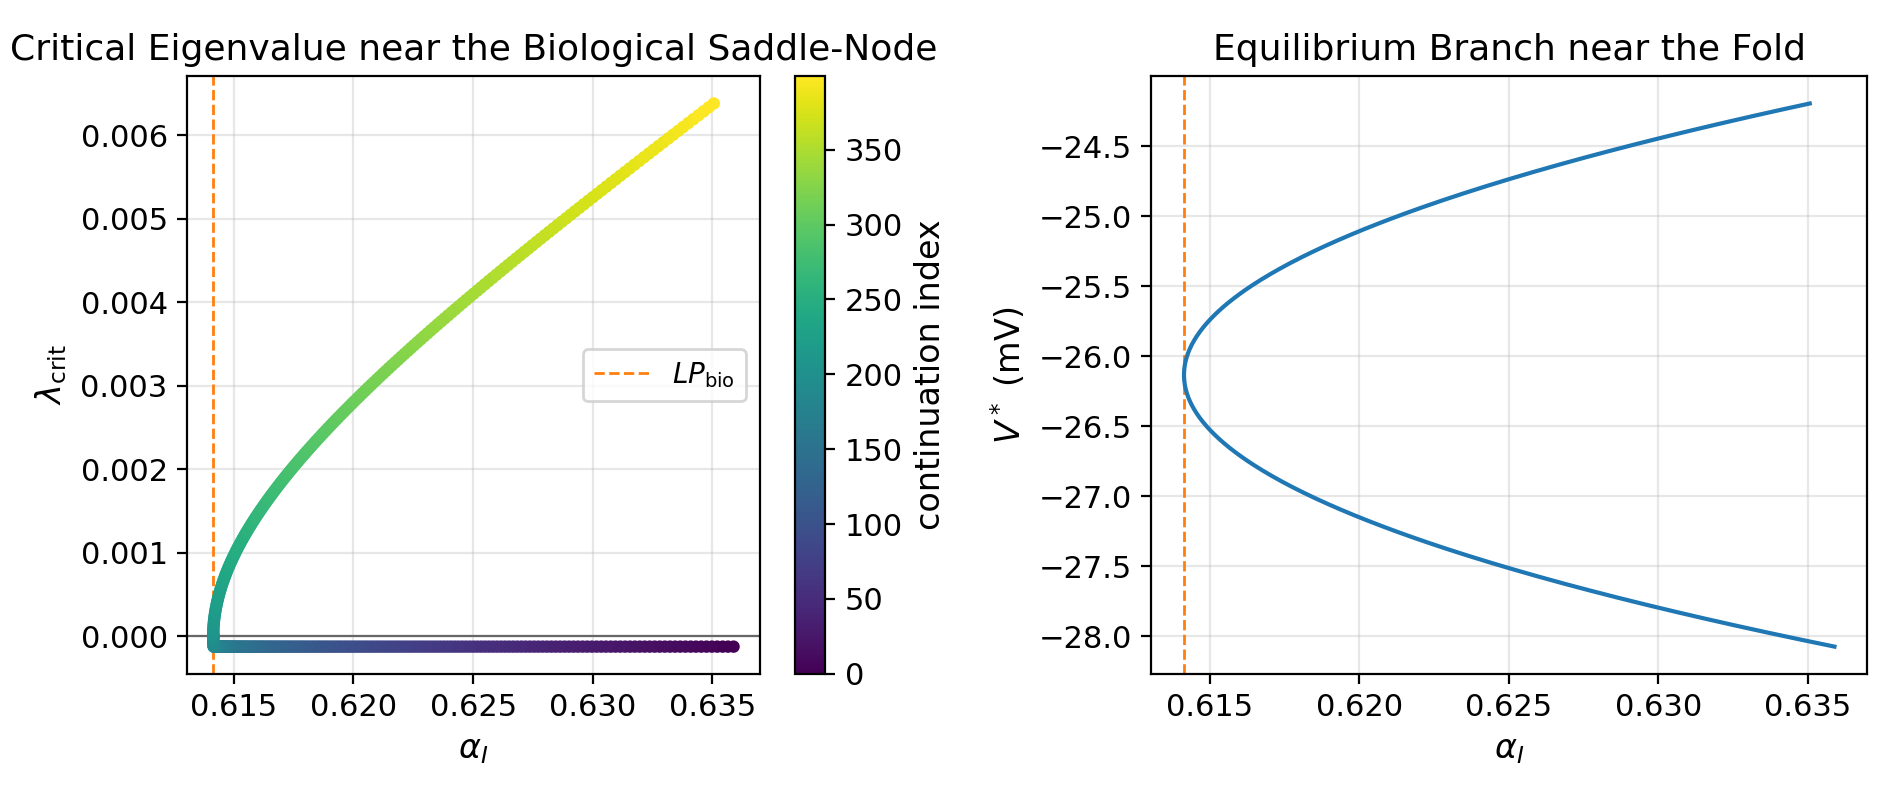

## 5. Hopf spectrum at $H_{\mathrm{bio}}$

Complete TTX ($\alpha_I = 0$) with free parameter $\alpha_P$. The biological Hopf $H_{\mathrm{bio}}$ lies near $\alpha_P \approx 0.2679$.

In [5]:

spec_h = load_csv("spectrum_Hbio.csv")
hopf_info = load_json("hopf_info.json")
print("H_bio spectrum:")
show_table(spec_h, cols=["index", "real", "imag", "abs", "critical"])
print("\nω_H = {:.6e}  (1/ms)".format(hopf_info["omega_H"]))
print("T_lin = 2π/ω_H = {:.6f} ms".format(hopf_info["T_lin_ms"]))
print("Spectral gap of non-critical modes from imag axis: {:.3e}".format(hopf_info["spectral_gap_imag"]))
print("Equilibrium residual: {:.3e}".format(hopf_info["residual_max"]))

htrack = load_csv("hopf_critical_track.csv")
# sign change of Re
res = np.array([float(r["Re_crit"]) for r in htrack])
ps = np.array([float(r["alpha_P"]) for r in htrack])
order = np.argsort(ps)
print("Re(λ_crit) at min α_P: {:.3e}, at max α_P: {:.3e}".format(res[order][0], res[order][-1]))
print("sign change across H_bio:", np.any(np.diff(np.sign(res[order])) != 0))


H_bio spectrum:
index | real        | imag         | abs         | critical
------+-------------+--------------+-------------+---------
4     | -6.2918e-13 | 0.000754758  | 0.000754758 | True    
5     | -6.2918e-13 | -0.000754758 | 0.000754758 | True    
1     | -0.0084582  | 0            | 0.0084582   | False   
6     | -0.012914   | 0            | 0.012914    | False   
3     | -0.0464046  | 0            | 0.0464046   | False   
2     | -0.0872696  | 0            | 0.0872696   | False   
0     | -0.387548   | 0            | 0.387548    | False   

ω_H = 7.547580e-04  (1/ms)
T_lin = 2π/ω_H = 8324.768152 ms
Spectral gap of non-critical modes from imag axis: 8.458e-03
Equilibrium residual: 3.469e-17
Re(λ_crit) at min α_P: -2.640e-05, at max α_P: 2.534e-05
sign change across H_bio: True


**Figure — Critical Eigenvalues near the Biological Hopf.**

Tracked critical conjugate pair versus $\alpha_P$. The real part crosses zero at $H_{\mathrm{bio}}$ while the imaginary part remains nonzero.

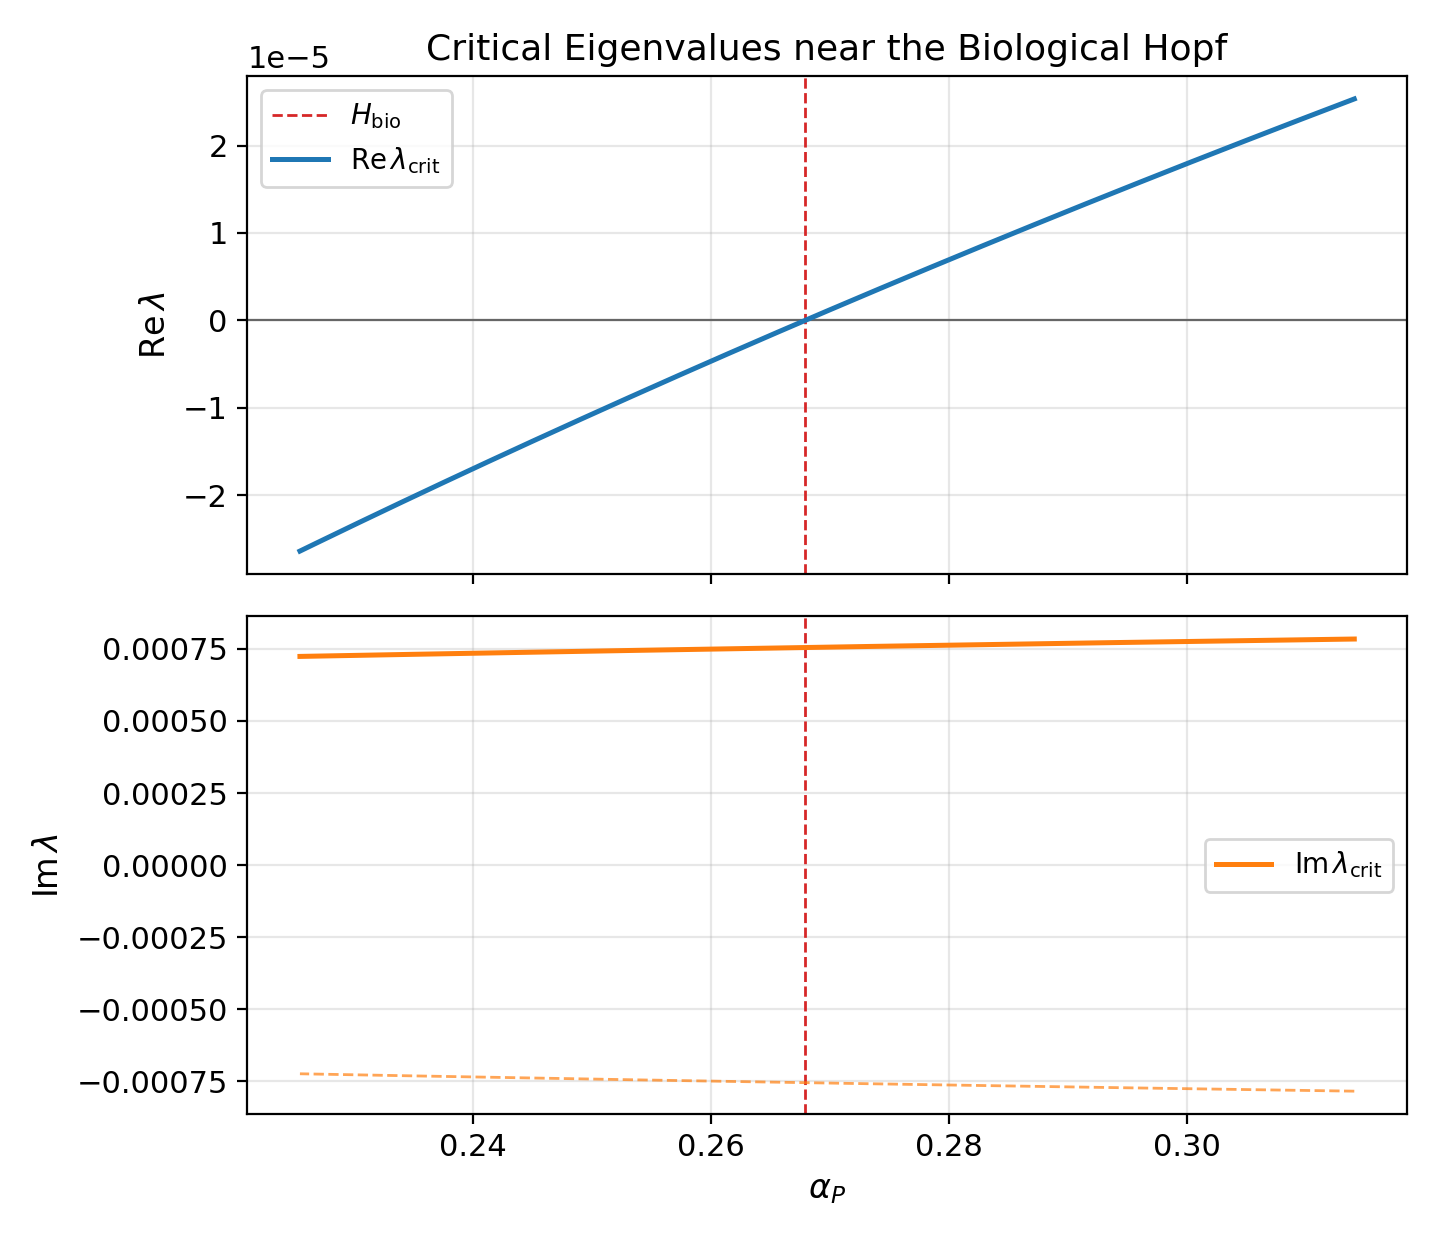

## 6. Hopf period prediction

At $H_{\mathrm{bio}}$,
$$
T_{\mathrm{lin}} = \frac{2\pi}{\omega_H},\qquad \omega_H = |\mathrm{Im}\,\lambda_H|.
$$
AUTO LC-C periods on the Hopf bubble are compared as cycle amplitude $V_{\max}-V_{\min}\to 0$. Time unit: milliseconds.

In [6]:

period = load_csv("hopf_period_comparison.csv")
print("Near-Hopf AUTO vs eigenvalue period:")
show_table(
    period[:12],
    cols=["alpha_P", "dist_from_Hbio", "amplitude_mV", "period_AUTO_ms", "period_Tlin_ms", "relative_error"],
)
errs = [float(r["relative_error"]) for r in period]
print("\nmin relative error = {:.3e}".format(min(errs)))
print("T_lin = {:.6f} ms".format(float(period[0]["period_Tlin_ms"])))


Near-Hopf AUTO vs eigenvalue period:
alpha_P  | dist_from_Hbio | amplitude_mV | period_AUTO_ms | period_Tlin_ms | relative_error
---------+----------------+--------------+----------------+----------------+---------------
0.26792  | 8.59769e-09    | 0.0014117    | 8324.77        | 8324.77        | 3.42433e-10   
0.26792  | 6.89043e-08    | 0.00423509   | 8324.77        | 8324.77        | 4.36388e-09   
0.26792  | 3.7032e-07     | 0.00988163   | 8324.77        | 8324.77        | 2.80734e-08   
0.267922 | 1.69656e-06    | 0.0211749    | 8324.77        | 8324.77        | 1.32414e-07   
0.267927 | 7.24261e-06    | 0.0437615    | 8324.77        | 8324.77        | 5.68744e-07   
0.267943 | 2.27953e-05    | 0.0776324    | 8324.78        | 8324.77        | 1.7924e-06    
0.267983 | 6.23977e-05    | 0.128446     | 8324.81        | 8324.77        | 4.90869e-06   
0.268049 | 0.000129297    | 0.184903     | 8324.85        | 8324.77        | 1.01744e-05   
0.26814  | 0.000220287    | 0.241363     | 

**Figure — Limit-Cycle Period near the Hopf Bifurcation.**

AUTO period approaches the eigenvalue prediction $T_{\mathrm{lin}}=2\pi/\omega_H$ as the limit-cycle voltage amplitude tends to zero.

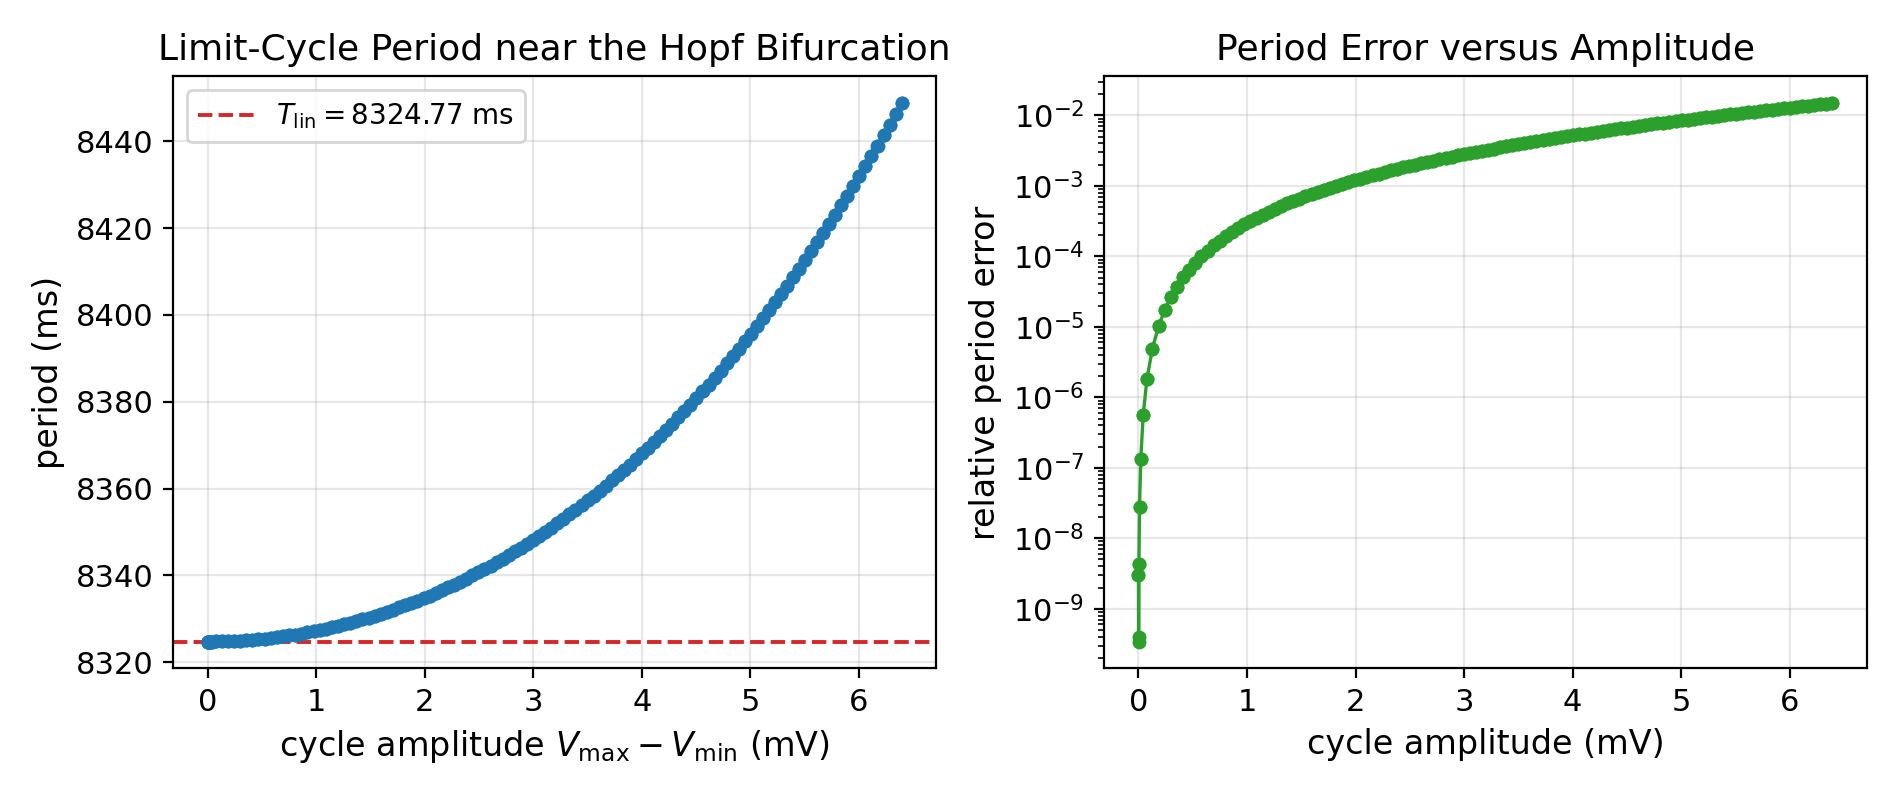

## 7. Hopf transversality

Centred finite differences of $\mathrm{d}\,\mathrm{Re}(\lambda_{\mathrm{crit}})/\mathrm{d}\alpha_P$ at several step sizes $h$, plus the semi-analytical formula
$$
\frac{\mathrm{d}\lambda}{\mathrm{d}\alpha_P}
=
w^{H}
\frac{\mathrm{d}J}{\mathrm{d}\alpha_P}
v
$$
with $w^{H}v=1$ and equilibrium dependence through $\mathrm{d}x^{*}/\mathrm{d}\alpha_P=-J^{-1}F_{\alpha_P}$.

In [7]:

trans = load_csv("hopf_transversality_fd.csv")
semi = load_json("hopf_transversality_semianalytic.json")
show_table(trans, cols=["h", "dRe_dmu", "Re_plus", "Re_minus", "Im_plus", "Im_minus"])
print("\nSemi-analytical dλ/dα_P = {:.6e} + {:.6e} i".format(
    semi["dlambda_dalpha_P_re"], semi["dlambda_dalpha_P_im"]
))
print("FD median dRe/dα_P = {:.6e}".format(np.median([float(r["dRe_dmu"]) for r in trans])))
print("Relative |FD - semi| / |semi| = {:.3e}".format(
    abs(np.median([float(r["dRe_dmu"]) for r in trans]) - semi["dlambda_dalpha_P_re"])
    / abs(semi["dlambda_dalpha_P_re"])
))


h      | dRe_dmu     | Re_plus     | Re_minus     | Im_plus     | Im_minus   
-------+-------------+-------------+--------------+-------------+------------
1e-05  | 0.000583566 | 5.83495e-09 | -5.83637e-09 | 0.000754765 | 0.000754751
3e-05  | 0.000583566 | 1.75056e-08 | -1.75083e-08 | 0.000754778 | 0.000754738
0.0001 | 0.000583566 | 5.83478e-08 | -5.83654e-08 | 0.000754826 | 0.00075469 
0.0003 | 0.000583566 | 1.74995e-07 | -1.75144e-07 | 0.000754963 | 0.000754553
0.001  | 0.000583568 | 5.82747e-07 | -5.84388e-07 | 0.000755439 | 0.000754075
0.003  | 0.00058358  | 1.74336e-06 | -1.75812e-06 | 0.000756796 | 0.000752702

Semi-analytical dλ/dα_P = 5.835661e-04 + 6.822413e-04 i
FD median dRe/dα_P = 5.835661e-04
Relative |FD - semi| / |semi| = 1.359e-07


## 8. Saddle-node nondegeneracy

At $LP_{\mathrm{bio}}$, left/right nullvectors satisfy $Jq=0$, $p^{\mathsf T}J=0$, $p^{\mathsf T}q=1$. Coefficients
$$
a = p^{\mathsf T} F_{\alpha_I},\qquad
b = \tfrac12 p^{\mathsf T} D_x^{2}F[q,q]
$$
are computed from the symbolic Hessian action.

In [8]:

sn_c = load_json("sn_coefficients.json")
print("a = {:.6e}".format(sn_c["a"]))
print("b = {:.6e}".format(sn_c["b"]))
print("σ_min(J) = {:.3e}".format(sn_c["sigma_min"]))
print("p·q = {:.6g}".format(sn_c["p_dot_q"]))
print("Nondegeneracy: |a|,|b| clearly nonzero relative to σ_min.")


a = -2.061501e-01
b = 1.152060e-03
σ_min(J) = 1.201e-13
p·q = 1
Nondegeneracy: |a|,|b| clearly nonzero relative to σ_min.


**Figure — Local Fold Geometry near the Biological Saddle-Node.**

EP-C voltage deviation from the fold versus $\Delta\alpha_I$, compared with the square-root scaling implied by the computed normal-form coefficients $a$ and $b$ (local qualitative comparison).

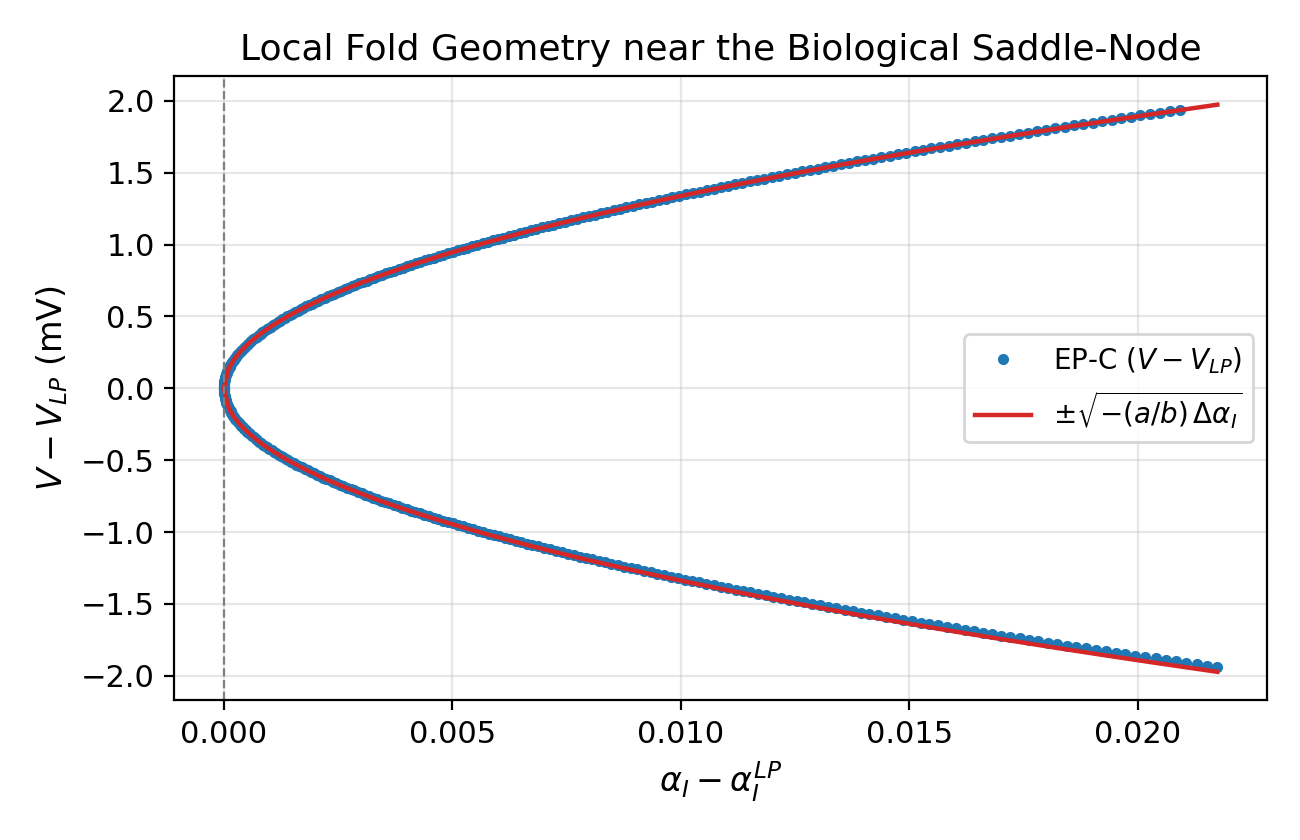

## 9. Optional strong extensions

In [9]:

evec = load_csv("hopf_eigenvector.csv")
print("Critical Hopf eigenvector (magnitudes / phases relative to V):")
show_table(evec, cols=["variable", "abs", "phase_rel_V_deg", "real", "imag"])


Critical Hopf eigenvector (magnitudes / phases relative to V):
variable | abs        | phase_rel_V_deg | real       | imag        
---------+------------+-----------------+------------+-------------
V        | 0.99822    | 0               | 0.99822    | 0           
X_K      | 0.00722772 | -3.35423        | 0.00721533 | -0.000422886
X_A      | 0.0199624  | -0.432436       | 0.0199618  | -0.000150664
Y_A      | 0.0419421  | 169.942         | -0.0412975 | 0.00732486  
X_P      | 0.0165231  | -80.5963        | 0.00269971 | -0.016301   
X_I      | 0.00553812 | -0.111585       | 0.00553811 | -1.07856e-05
Y_I      | 0.0323105  | 174.901         | -0.0321826 | 0.00287178  


## 10. Summary of numerical checks

In [10]:

summary = load_json("summary_checks.json")
for k, v in summary.items():
    if isinstance(v, float):
        print(f"{k:40s} {v:.6g}")
    else:
        print(f"{k:40s} {v}")

checks = [
    ("Jacobian validation gate", bool(summary["jacobian_validation_pass"])),
    ("Hopf Im(λ) ≠ 0 / T_lin finite", np.isfinite(summary["T_lin_ms"]) and summary["H_bio_omega"] > 0),
    ("AUTO period → T_lin", summary["near_hopf_min_rel_period_error"] < 1e-6),
    ("Hopf transversality ≠ 0", abs(summary["transversality_dRe_median"]) > 1e-6),
    ("FD ↔ semi-analytic dRe", abs(summary["transversality_dRe_median"] - summary["semianalytic_dRe"])
        / abs(summary["semianalytic_dRe"]) < 1e-4),
    ("SN λ_crit ≈ 0", summary["sn_lambda_crit_abs"] < 1e-8),
    ("SN gap > 0", summary["sn_gap"] > 1e-6),
    ("SN a ≠ 0", abs(summary["sn_a"]) > 1e-6),
    ("SN b ≠ 0", abs(summary["sn_b"]) > 1e-6),
]
print("\nChecklist:")
for name, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")


jacobian_validation_pass                 1
H_bio_omega                              0.000754758
T_lin_ms                                 8324.77
near_hopf_min_rel_period_error           3.42433e-10
transversality_dRe_median                0.000583566
semianalytic_dRe                         0.000583566
sn_a                                     -0.20615
sn_b                                     0.00115206
sn_lambda_crit_abs                       1.26588e-10
sn_gap                                   0.000125041

Checklist:
  [PASS] Jacobian validation gate
  [PASS] Hopf Im(λ) ≠ 0 / T_lin finite
  [PASS] AUTO period → T_lin
  [PASS] Hopf transversality ≠ 0
  [PASS] FD ↔ semi-analytic dRe
  [PASS] SN λ_crit ≈ 0
  [PASS] SN gap > 0
  [PASS] SN a ≠ 0
  [PASS] SN b ≠ 0


### Reproducibility

```bash
# Host EP-C windows
./.venv/bin/python scripts/run_08_epc_local_windows.py

# Docker AUTO LC-C (container jupyter-lab, CWD /notebooks)
docker exec -w /notebooks jupyter-lab python3 scripts/run_08_hopf_lc_samples.py

# Analysis + figures
./.venv/bin/python scripts/run_08_jacobian_hopf_analysis.py

# Rebuild this notebook attachments
./.venv/bin/python scripts/build_08_jacobian_hopf_nb.py
```
